In [1]:
import pandas as pd

In [4]:
df = pd.read_csv('student_dataset.csv')

In [5]:
df


,Name,IQ,CGPA,Placement
0,Talha Hussain,107,3.27,Placed
1,Talha Farooqi,94,2.67,Not Placed
2,Hassan Ahmed,72,2.28,Not Placed
3,Omar Sheikh,82,2.71,Not Placed
4,Faisal Malik,95,2.85,Not Placed
...,...,...,...,...
495,Imran Shah,77,1.94,Not Placed
496,Saad Ali,89,1.63,Not Placed
497,Imran Iqbal,122,3.48,Placed
498,Hira Chaudhry,118,3.05,Placed


In [7]:
df.head()

,Name,IQ,CGPA,Placement
0,Talha Hussain,107,3.27,Placed
1,Talha Farooqi,94,2.67,Not Placed
2,Hassan Ahmed,72,2.28,Not Placed
3,Omar Sheikh,82,2.71,Not Placed
4,Faisal Malik,95,2.85,Not Placed


In [10]:
df.shape

(500, 4)

In [11]:
import matplotlib.pyplot as plt


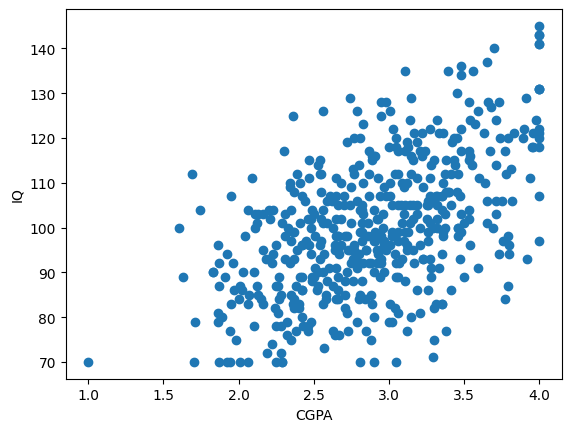

In [14]:
plt.scatter(df['CGPA'], df['IQ'])
plt.xlabel('CGPA')
plt.ylabel('IQ')
plt.show()

In [15]:
df.columns.tolist()

['Name', 'IQ', 'CGPA', 'Placement']

In [16]:
df.columns = df.columns.str.lower()

In [18]:
df.columns.tolist()

['name', 'iq', 'cgpa', 'placement']

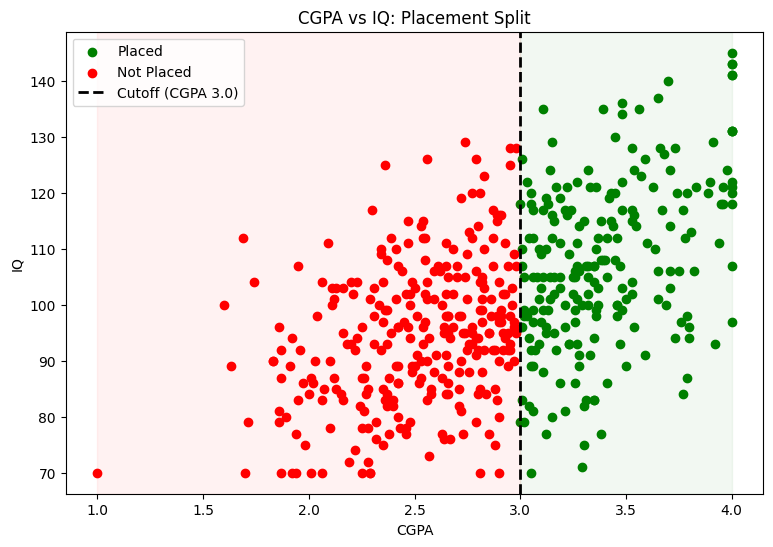

In [20]:
plt.figure(figsize=(9, 6))

placed = df[df['placement'] == 'Placed']
not_placed = df[df['placement'] == 'Not Placed']
plt.scatter(placed['cgpa'], placed['iq'], color='green', label='Placed')
plt.scatter(not_placed['cgpa'], not_placed['iq'], color='red', label='Not Placed')

plt.axvline(x=3.0, color='black', linestyle='--', linewidth=2, label='Cutoff (CGPA 3.0)')
plt.axvspan(df['cgpa'].min(), 3.0, color='red', alpha=0.05)
plt.axvspan(3.0, df['cgpa'].max(), color='green', alpha=0.05)

plt.xlabel('CGPA')
plt.ylabel('IQ')
plt.title('CGPA vs IQ: Placement Split')
plt.legend()
plt.show()

In [21]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [22]:
X = df[['iq', 'cgpa']]    # information the model learns from
y = df['placement']       # the answer we want the model to predict

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=50, random_state=42, stratify=y)

print(X_train.shape)   # should show (450, 2)
print(X_test.shape)    # should show (50, 2)

(450, 2)
(50, 2)


In [24]:
model = LogisticRegression()
model.fit(X_train, y_train)

LogisticRegression()

In [25]:
y_pred = model.predict(X_test)

In [26]:
print('Accuracy:', accuracy_score(y_test, y_pred))

Accuracy: 0.98


In [27]:
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[28  0]
 [ 1 21]]
              precision    recall  f1-score   support

  Not Placed       0.97      1.00      0.98        28
      Placed       1.00      0.95      0.98        22

    accuracy                           0.98        50
   macro avg       0.98      0.98      0.98        50
weighted avg       0.98      0.98      0.98        50



In [28]:
result = X_test.copy()
result['actual'] = y_test
result['predicted'] = y_pred
result[result['actual'] != result['predicted']]   # shows only the wrong ones

,iq,cgpa,actual,predicted
447,96,3.01,Placed,Not Placed


In [29]:
print('Train accuracy:', model.score(X_train, y_train))
print('Test accuracy :', model.score(X_test, y_test))

Train accuracy: 0.9888888888888889
Test accuracy : 0.98
